# Load Xenium Output and Save as SpatialData and AnnData

The dataset has been deposited in NCBI GEO (accession: GSEXXXXXX). The files available from GEO were generated after running the following section, so you can skip this section if you use the GEO-deposited data.

In [ ]:
# import os
# from spatialdata_io import xenium
# from spatialdata_io import xenium_aligned_image

# path = "/mnt/d/data001/xenium_IPF/work space/" # path to your workspace

# # Variable Declaration
# sample_symbols =["A1", "A2", "B1", "C1", "C2", "D1"]

# # Ouput directories
# os.makedirs(f"{path}SpatialData", exist_ok=True)
# os.makedirs(f"{path}AnnData", exist_ok=True)

# for sn in sample_symbols:
#     # load xenium output data
#     # The xenium output directory for each sample has been moved to the workspace in advance with a sample name of your choice.
#     sdata = xenium(path+sn, cells_as_circles=False)

#     # Add H&E-stain figures. 
#     # Set pathes to ome.tif file and alignment file.
#     # Alignment file may not be contained in Xenium output data. Run Xenium Explorer and output alignment file.
#     sdata.images["HE"] = xenium_aligned_image(image_path=f"{path}{sn}/HE.ome.tif", alignment_file=f"{path}{sn}/matrix.csv")

#     adata = sdata.tables["table"]

#     sdata.write(f"{path}SpatialData/{sn}", overwrite=True)
#     adata.write(f"{path}AnnData/{sn}.h5ad")
    

# Integrate AnnData

In [1]:
import scanpy as sc
import anndata
import numpy as np

path = "/mnt/d/data001/xenium_IPF/work space/" # path to your workspace

# Option
sc.settings.verbosity = 3

# Variable Declaration
sample_symbols =["A1", "A2", "B1", "C1", "C2", "D1"]

In [2]:
adata_list=[sc.read_h5ad(f"{path}AnnData/{sn}.h5ad") for sn in sample_symbols]
for n, ss in enumerate(sample_symbols):
    adata_list[n].obs_names=adata_list[n].obs["cell_id"].str.removesuffix("-1")
    adata_list[n].obs["sample"]=ss

/home/s_nakamura/test_env/lib/python3.12/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [3]:
# Quality control
tc_p = 0.95  # Cut off the ratio of transcript_counts to total_counts
tc_c = 15  # The value of minimum transcript_counts 

for ad in adata_list:
    ad.obs["tc_ratio"]=ad.obs["transcript_counts"]/ad.obs["total_counts"]
    print(ad.obs["sample"].iloc[0]+":", "low_quality_counts", np.sum(ad.obs["tc_ratio"]< tc_p), "|", "transcript_counts", np.sum(ad.obs["transcript_counts"] < tc_c), "| total_cell_counts", ad.shape[0])

adata_list_qc=[ad[ad.obs["tc_ratio"] > tc_p] for ad in adata_list]
adata_list_qc=[ad[ad.obs["transcript_counts"] >= tc_c] for ad in adata_list_qc]

A1: low_quality_counts 57 | transcript_counts 909 | total_cell_counts 164135
A2: low_quality_counts 76 | transcript_counts 1979 | total_cell_counts 95263
B1: low_quality_counts 41 | transcript_counts 983 | total_cell_counts 86922
C1: low_quality_counts 120 | transcript_counts 2524 | total_cell_counts 111827
C2: low_quality_counts 213 | transcript_counts 4571 | total_cell_counts 137174
D1: low_quality_counts 185 | transcript_counts 5689 | total_cell_counts 105394


In [4]:
adata_list_n = [
    anndata.AnnData(
        X=ad.X,
        obs=ad.obs[['transcript_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', "sample"]],
        var=ad.var
    )
    for ad in adata_list_qc
]

In [5]:
adata = anndata.concat(adata_list_n, label="batch", index_unique="-", join="outer", merge="same")

In [6]:
adata.write(f"{path}AnnData/integrated_anndata.h5ad")

# Initial Clustering of All Cells

In [1]:
import matplotlib.pyplot as plt
import matplotlib
import os
import numpy as np
import scanpy as sc
import anndata
import pandas as pd

path = "/mnt/d/data001/xenium_IPF/work space/" # path to your workspace

# figure directory
os.makedirs(f"{path}Figure", exist_ok=True)
os.makedirs(f"{path}CSV", exist_ok=True)

# Option
sc.settings.verbosity = 3
%matplotlib ipympl
plt.rcParams["font.family"] = "Fira Sans" 


In [2]:
adata = sc.read_h5ad(f"{path}AnnData/integrated_anndata.h5ad")

In [3]:
# pearson_residual
adata.raw = adata.copy()
sc.experimental.pp.highly_variable_genes(adata, flavor="pearson_residuals", n_top_genes=2000, batch_key="sample")
sc.experimental.pp.normalize_pearson_residuals(adata)
sc.pp.pca(adata, n_comps=50, mask_var="highly_variable")

extracting highly variable genes
--> added
    'highly_variable', boolean vector (adata.var)
    'highly_variable_rank', float vector (adata.var)
    'highly_variable_nbatches', int vector (adata.var)
    'highly_variable_intersection', boolean vector (adata.var)
    'means', float vector (adata.var)
    'variances', float vector (adata.var)
    'residual_variances', float vector (adata.var)
computing analytic Pearson residuals on adata.X
    finished (0:00:57)
computing PCA
    with n_comps=50
    finished (0:01:00)


In [4]:
sc.external.pp.harmony_integrate(adata, "sample")
adata.obsm['X_pca'] = adata.obsm['X_pca_harmony']

2025-12-13 23:58:28,902 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-12-13 23:59:14,846 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-12-13 23:59:17,120 - harmonypy - INFO - Iteration 1 of 10
2025-12-14 00:03:20,083 - harmonypy - INFO - Iteration 2 of 10
2025-12-14 00:07:17,275 - harmonypy - INFO - Iteration 3 of 10
2025-12-14 00:11:20,817 - harmonypy - INFO - Iteration 4 of 10
2025-12-14 00:15:05,110 - harmonypy - INFO - Iteration 5 of 10
2025-12-14 00:17:06,954 - harmonypy - INFO - Iteration 6 of 10
2025-12-14 00:18:44,572 - harmonypy - INFO - Converged after 6 iterations


In [5]:
sc.pp.neighbors(adata, n_neighbors=50)
sc.tl.umap(adata, min_dist=0.2)
sc.tl.leiden(adata, resolution=1.6, flavor="igraph", n_iterations=-1, directed=False)

computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:03:53)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:09:02)
running Leiden clustering
    finished: found 42 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:01:05)


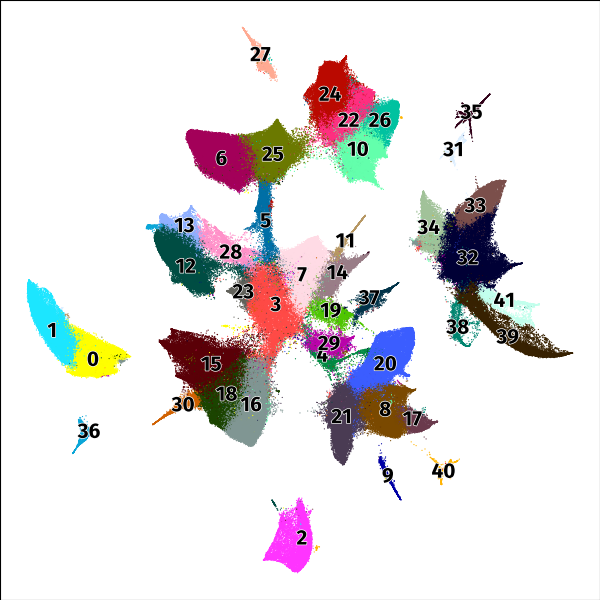

In [6]:
fig, ax = plt.subplots(1,1, figsize=(6,6))
plt.subplots_adjust(left=0, right=1, bottom=0, top=1)
sc.pl.umap(adata,color="leiden", legend_loc="on data", s=3, ax=ax, legend_fontoutline=True, legend_fontsize=15)
ax.set_title("All cell clustering", fontsize=22)
ax.axis("off")
plt.subplots_adjust(left=0, right=1, bottom=0, top=1)
plt.savefig(f"{path}Figure/011_All_leiden_umap.png", dpi=500, format="png", bbox_inches=None)

In [7]:
adata.X=adata.raw.X.copy()

In [8]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

normalizing counts per cell
    finished (0:00:00)


In [10]:
sc.tl.dendrogram(adata, groupby="leiden")
sc.tl.rank_genes_groups(adata, groupby="leiden", use_raw=False, n_genes=1000, method='wilcoxon')

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden']`
ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:03:25)


/home/s_nakamura/test_env/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:435: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/home/s_nakamura/test_env/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:437: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/home/s_nakamura/test_env/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:440: PerformanceWarning: DataFrame is h

In [11]:
rg = adata.uns["rank_genes_groups"]
groups = list(rg["names"].dtype.names)  

In [12]:
gene_to_col = {g: i for i, g in enumerate(adata.var_names)}

frac_by_group = {}
obs_grp = adata.obs["leiden"].values

for g in groups:
    mask = (obs_grp == g)
    n_cells = int(mask.sum())
    if n_cells == 0:
        frac_by_group[g] = np.zeros(adata.n_vars, dtype=float)
        continue

    subX = adata.X[mask, :].tocsr()
    hits = subX.copy()
    hits.data = (hits.data > 0).astype(np.int8)
    frac = np.asarray(hits.sum(axis=0)).ravel() / n_cells

    frac_by_group[g] = frac

In [13]:
deg_num = 1000
leiden_deg_df = pd.DataFrame(columns=[i for i in range(deg_num*len(groups))], index=["leiden", "genes", "fractions", 'scores', 'pvals', 'pvals_adj', 'logfoldchanges'])

for n, g in enumerate(groups):
    for i in range(deg_num):
        leiden_deg_df.loc["leiden", i+deg_num*n]=g
        leiden_deg_df.loc["genes", i+deg_num*n]=rg["names"][i][n]
        leiden_deg_df.loc["fractions", i+deg_num*n]=frac_by_group[g][gene_to_col[rg["names"][i][n]]]
        for t in ['scores', 'pvals', 'pvals_adj', 'logfoldchanges']:
            leiden_deg_df.loc[t, i+deg_num*n]=rg[t][i][n].astype(np.float64)
leiden_deg_df.T.to_csv(f"{path}CSV/011_leiden_degs.csv", index=False)

In [24]:
all_cluster_dict = {
    "Epithelial": ["#E41A1C", (9.3, 11.2)],
    "Fibroblast": ["#377EB8", (-4.6, 5)], 
    "SMC/Pericyte": ["#A6D854", (-2, 15.7)], 
    "Endothelial": ["#D95F02", (3, 17.5)],  
    "CD8+ T": ["#8DA0CB", (0.7,10.7)], 
    "CD4+ T": ["#E5C494", (-1.1, 8)], 
    "Treg": ["#A6761D", (-3.6, 9.1)], 
    "NK": ["#1B9E77", (3.5, 10.1)], 
    "B cell": ["#FC8D62", (-6.1, 10.7)], 
    "Plasma cell": ["#40B0A6", (-11.5, 7.5)],
    "Monocyte/MΦ": ["#66C2A5", (5, 3.8)], 
    "pDC": ["#A65628", (3.6, 12)], 
    "cDC1": ["#FFD92F", (5.4, 0)], 
    "cDC2": ["#FF7F00", (8.1, 2.4)], 
    "mregDC": ["#F781BF", (5.9, 9)], 
    "moDC": ["#FFFF33", (3.5,7.5)], 
    "FRC": ["#E7298A", (-1.1, 12.7)], 
    "FDC": ["#984EA3", (-2.9, 11.4)], 
    "CXCR1+ neut.": ["#7570B3", (13.1, 18)], 
    "CXCR2+ neut.": ["#4DAF4A", (12.5, 16.2)], 
    "DEFA1+ neut.": ["#66A61E", (11.5, 0)], 
    "Mast cell": ["#E78AC3", (0.6, -2.7)], 
    "SOX2-OT high": ["#999999", (2.8, 6.1)]
}

annot = {
    '0': "Plasma cell", '1': "Plasma cell", '2': "Mast cell", '3': "CD4+ T", '4': "Monocyte/MΦ", 
    '5': "FRC", '6': "SMC/Pericyte", '7': "CD8+ T", '8':"Monocyte/MΦ", '9': "cDC1", 
    '10': "Endothelial", '11': "pDC", '12': "B cell", '13': "B cell", '14': "NK", 
    '15': "Fibroblast", '16': "Fibroblast", '17': "cDC2", '18':"Fibroblast", '19': "moDC", 
    '20': "Monocyte/MΦ", '21': "Monocyte/MΦ", '22': "Endothelial", '23': "Treg", '24': "Endothelial", 
    '25': "SMC/Pericyte", '26': "Endothelial", '27': "Endothelial", '28':"FDC", '29':"SOX2-OT high",
    '30': "Fibroblast", '31': "CXCR2+ neut.", '32': "Epithelial", '33': "Epithelial", '34': "Epithelial",
    '35': "CXCR1+ neut.", '36': "B cell", '37': "mregDC", '38': "Epithelial", '39': "Epithelial", 
    '40': "DEFA1+ neut.", "41": "Epithelial"
}

In [25]:
adata.obs['cell_type'] = adata.obs['leiden'].map(annot).astype('category')
adata.obs['cell_type'] = pd.Categorical(values=adata.obs['cell_type'], categories=all_cluster_dict.keys(), ordered=True)
adata.uns["cell_type_colors"] =[vals[0] for key, vals in all_cluster_dict.items()]

In [26]:
major_cluster_dict={
    "Epithelial": "Epithelial",
    "Fibroblast": "Fibroblast",
    "SMC/Pericyte": "SMC/Pericyte",
    "Endothelial": "Endothelial",
    "Monocyte/MΦ": "Monocyte/MΦ",

    "CD4+ T": "NK/T cell",
    "CD8+ T": "NK/T cell",
    "Treg": "NK/T cell",
    "NK": "NK/T cell",

    "B cell": "B/Plasma",
    "Plasma cell": "B/Plasma",
    
    "pDC": "Dendritic cell",
    "cDC1": "Dendritic cell",
    "cDC2": "Dendritic cell",
    "mregDC": "Dendritic cell",
    "moDC": "Dendritic cell",
    
    "CXCR1+ neut.": "Granulocyte",
    "CXCR2+ neut.": "Granulocyte",
    "DEFA1+ neut.": "Granulocyte",
    "Mast cell": "Granulocyte",

    "FRC": "FRC",
    
    "FDC": "FDC",
    
    "SOX2-OT high": "SOX2-OT high"
}

major_cluster_colors={
    "Epithelial": "#E41A1C",  
    "Fibroblast": "#377EB8",  
    "SMC/Pericyte": "#4DAF4A", 
    "Endothelial": "#984EA3",  
    "Monocyte/MΦ": "#FF7F00",  
    "NK/T cell": "#FFFF33",  
    "B/Plasma": "#F781BF",  
    "Dendritic cell": "#E7298A",  
    "Granulocyte": "#66C2A5",  
    "FRC": "#A65628",
    "FDC": "#8DA0CB",   
    "SOX2-OT high": "#999999",
}


In [27]:
adata.obs['cell_type_major'] = adata.obs['cell_type'].map(major_cluster_dict).astype('category')
adata.obs['cell_type_major'] = pd.Categorical(values=adata.obs['cell_type_major'], categories=list(major_cluster_colors.keys()), ordered=True)
adata.uns["cell_type_major_colors"] = list(major_cluster_colors.values())

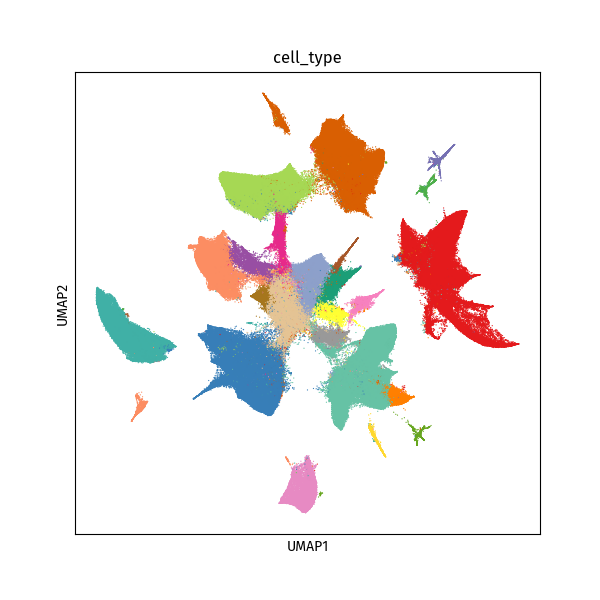

In [28]:
fig, ax = plt.subplots(1,1, figsize=(6,6))
sc.pl.umap(adata,color="cell_type", legend_loc=None, s=3, ax=ax)

for key, (_, xy) in all_cluster_dict.items():
    ax.text(xy[0], xy[1], key,
            fontsize=14,
            ha='center',
            va='center',
            fontweight="bold",
            path_effects=[matplotlib.patheffects.withStroke(linewidth=3, foreground='white', capstyle="round")]
           )

plt.title("")
plt.axis("off")
plt.subplots_adjust(left=0, right=1, bottom=0, top=1)
plt.savefig(f"{path}Figure/011_All_celltype_umap.png", dpi=500, format="png", bbox_inches=None)

In [29]:
adata.uns["sample_colors"] = ['#F6AA00', '#FFF100', '#03AF7A', '#005AFF', '#4DC4FF', '#804000']

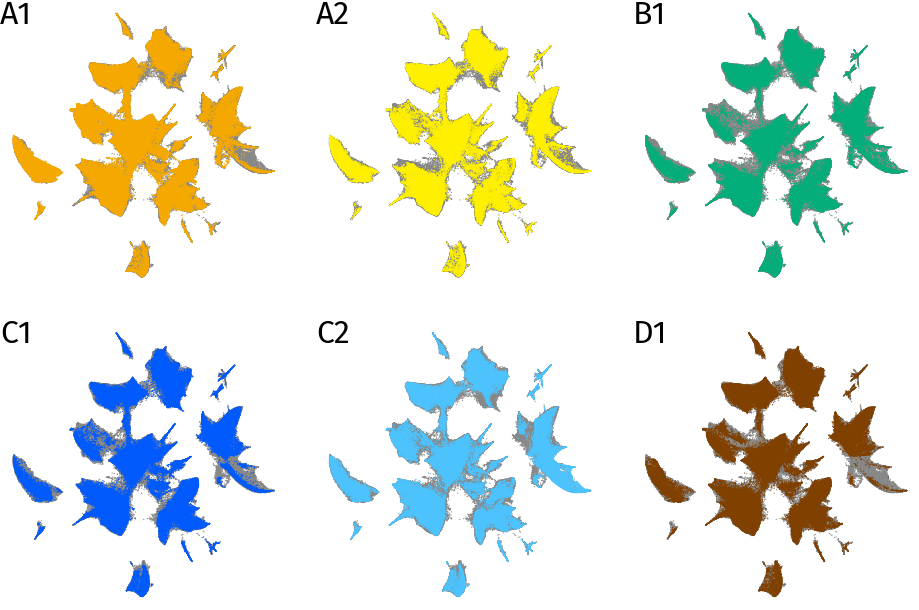

In [31]:
fig, axes = plt.subplots(2,3, figsize=(9.2, 6.1))
axes = axes.flatten()
for ax,sam in zip(axes,adata.obs["sample"].cat.categories):
    sc.pl.umap(adata, color="sample", groups=sam, na_color="#888888", na_in_legend=False, legend_loc=None, title="", ax=ax, s=3, show=False)
    ax.axis("off")
    ax.text(s=sam, x=ax.get_xlim()[0], y=ax.get_ylim()[1], va="top", ha="left", fontsize=23)
plt.subplots_adjust(left=0, right=1, bottom=0, top=1, wspace=0.1, hspace=0.1)
plt.show()
plt.savefig(f"{path}Figure/011_All_sample_umap.png", dpi=500, format="png", bbox_inches=None)

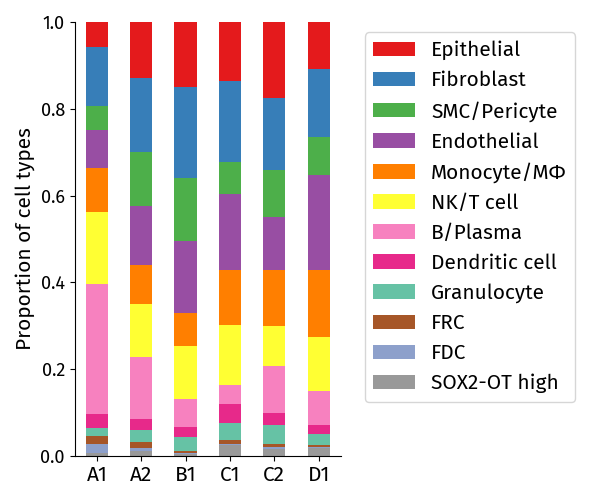

In [36]:
ct_counts = pd.crosstab(adata.obs['sample'], adata.obs['cell_type_major'])
ct_props = ct_counts.div(ct_counts.sum(axis=1), axis=0)

cell_type_order = ct_counts.columns.tolist()
ct_props = ct_props[cell_type_order[::-1]]

colors = adata.uns["cell_type_major_colors"]
colors_for_plot = colors[::-1]

ax = ct_props.plot(kind='bar', stacked=True, figsize=(6, 5), color=colors_for_plot)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], title='', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=15)

plt.ylabel('Proportion of cell types', fontsize=15)
plt.xlabel('')
plt.ylim(0,1)
plt.tick_params("x", labelsize=15, rotation=0)
plt.tick_params("y", labelsize=13)
plt.tight_layout()
plt.show()

plt.savefig(f"{path}Figure/011_All_sample_stackedbar.png", dpi=500, format="png", bbox_inches=None)

In [37]:
adata.write(f"{path}AnnData/1st_clustering.h5ad")

In [38]:
celltype_df = adata.obs[["cell_type", "cell_type_major", "sample", "batch"]]
celltype_df.to_csv(f"{path}CSV/011_1st_clustering.csv", index=True)